# Spam Message Classification: KNN vs SVM vs Naive Bayes

**Goal:** classify messages as spam (`spam_label = 1`) or legitimate (`0`) from engineered message, sender and time features, and compare three families of classifiers: **distance-based (KNN)**, **margin-based (SVM)** and **probabilistic (Naive Bayes)**.

**Dataset:** 5,200 messages, 16 columns (`message_intelligence_dataset.csv`).

**Notebook map:** Part A theory, Part B data preparation, Part C KNN, Part D SVM, Part E Naive Bayes, Part F comparison, Part G final analysis.

## Part A: Probability & Conceptual Foundation (Theory)

**1. Conditional probability.**
$P(A\mid B)=\dfrac{P(A\cap B)}{P(B)}$ is the probability that event A occurs given that B has already occurred, for $P(B)>0$. Example: $P(\text{spam}\mid \text{message contains a URL})$.

**2. Bayes' theorem and why it matters for classification.**
$P(y\mid x)=\dfrac{P(x\mid y)\,P(y)}{P(x)}$. It turns the easy-to-estimate *likelihood* $P(x\mid y)$ and *prior* $P(y)$ into the *posterior* $P(y\mid x)$ that a classifier actually needs. Predicting $\arg\max_y P(x\mid y)P(y)$ is the Bayes decision rule, which is optimal if the probabilities are correct. It also yields calibrated-style confidence scores and lets priors (class imbalance, costs) be incorporated explicitly.

**3. Naive Bayes assumptions.**
(i) *Conditional independence*: features are independent given the class, so $P(x\mid y)=\prod_j P(x_j\mid y)$. (ii) Each feature follows an assumed distribution per class (Gaussian for GaussianNB). (iii) Training and test data come from the same distribution, and the class prior is estimated from the training data. The independence assumption is rarely exactly true but often works well in practice.

**4. Working principle.**
- **KNN:** a lazy, non-parametric learner. It stores the training set; to classify a point it finds the *K* closest training points (by a distance metric such as Euclidean) and takes a majority vote. Small K gives low bias / high variance; large K the reverse. Feature scaling is essential.
- **SVM:** finds the hyperplane that maximises the *margin* between classes; only the *support vectors* (points on or inside the margin) define it. Soft margin (parameter C) tolerates violations; kernels (RBF, polynomial) implicitly map data to a higher-dimensional space to get non-linear boundaries.

**5. Distance-based vs probabilistic vs margin-based classifiers.**

| | Distance-based (KNN) | Probabilistic (Naive Bayes) | Margin-based (SVM) |
|---|---|---|---|
| Idea | Similar points share labels | Model $P(y\mid x)$ via Bayes' rule | Maximise separation margin |
| Training | None (stores data) | Very fast (estimate means, variances, priors) | Quadratic optimisation, slower |
| Prediction | Slow (search neighbours) | Very fast | Fast (uses support vectors) |
| Needs scaling | Yes | No | Yes |
| Output | Vote share | Class probabilities | Signed distance to boundary |
| Interpretability | Case-based | High (per-feature likelihoods) | Low with non-linear kernels |
| Key weakness | Noisy / irrelevant features, cost at scale | Independence assumption | Hyper-parameter tuning, no native probabilities |

## Part B: Dataset Understanding & Preparation

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logsumexp

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, classification_report)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.max_colwidth', 110)
RANDOM_STATE = 42
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

In [2]:
df = pd.read_csv('../data/message_intelligence_dataset.csv', parse_dates=['timestamp'])
print('Shape:', df.shape)
display(df.head())
display(df.dtypes.to_frame('dtype').T)

Shape: (5200, 16)


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updated proposal. Thanks. https://company.portal/docs/6283,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline. next Monday. Let me know.,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Monday. Please confirm.,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 AM. Please confirm.,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedback? the quarterly review. Let me know.,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
dtype,int64,str,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,datetime64[us],int64,int64,int64


Missing values per column (only columns with gaps):
                         missing   pct
sender_activity_score        106  2.04
sender_account_age_days      113  2.17
messages_sent_last_24h       162  3.12

Duplicate rows (excluding message_id): 0
Unique message texts: 1487 of 5200

Class balance:
 spam_label
legit (0)    4227
spam (1)      973
Name: count, dtype: int64 
Spam share: 18.7%


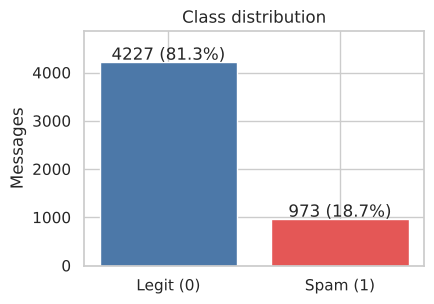

In [3]:
# Missing values, duplicates and class balance
miss = df.isna().sum()
print('Missing values per column (only columns with gaps):')
print(miss[miss > 0].to_frame('missing').assign(pct=lambda d: (100 * d.missing / len(df)).round(2)))
print('\nDuplicate rows (excluding message_id):', df.drop(columns='message_id').duplicated().sum())
print('Unique message texts:', df.message_text.nunique(), 'of', len(df))

counts = df.spam_label.value_counts().sort_index()
print('\nClass balance:\n', counts.rename({0: 'legit (0)', 1: 'spam (1)'}), '\nSpam share: %.1f%%' % (100 * df.spam_label.mean()))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(['Legit (0)', 'Spam (1)'], counts.values, color=['#4C78A8', '#E45756'])
for i, v in enumerate(counts.values): ax.text(i, v + 40, f'{v} ({100*v/len(df):.1f}%)', ha='center')
ax.set_ylabel('Messages'); ax.set_title('Class distribution'); ax.set_ylim(0, counts.max() * 1.15)
savefig('01_class_distribution')

**Interpretation.** Legitimate messages outnumber spam about 4.3 to 1 (4,227 vs 973, 18.7% spam). A model that always answered "legit" would already be 81.3% accurate, so accuracy alone is a weak yardstick here and we report precision, recall and F1 for the spam class. The split is stratified so train and test keep the same 18.7%.

### Exploratory analysis
Feature distributions split by class, then correlations. This guides which features matter and which models may struggle.

spam_label,legit mean,spam mean,ratio spam/legit
message_length,74.84,75.88,1.01
word_count,11.61,10.78,0.93
num_urls,0.08,0.74,8.80
num_digits,1.16,3.96,3.42
num_special_chars,0.00,1.30,NaN
spam_keyword_score,0.00,1.32,NaN
legit_keyword_score,1.01,0.00,0.00
sender_activity_score,54.77,55.11,1.01
sender_account_age_days,346.89,78.54,0.23
messages_sent_last_24h,6.03,18.25,3.03


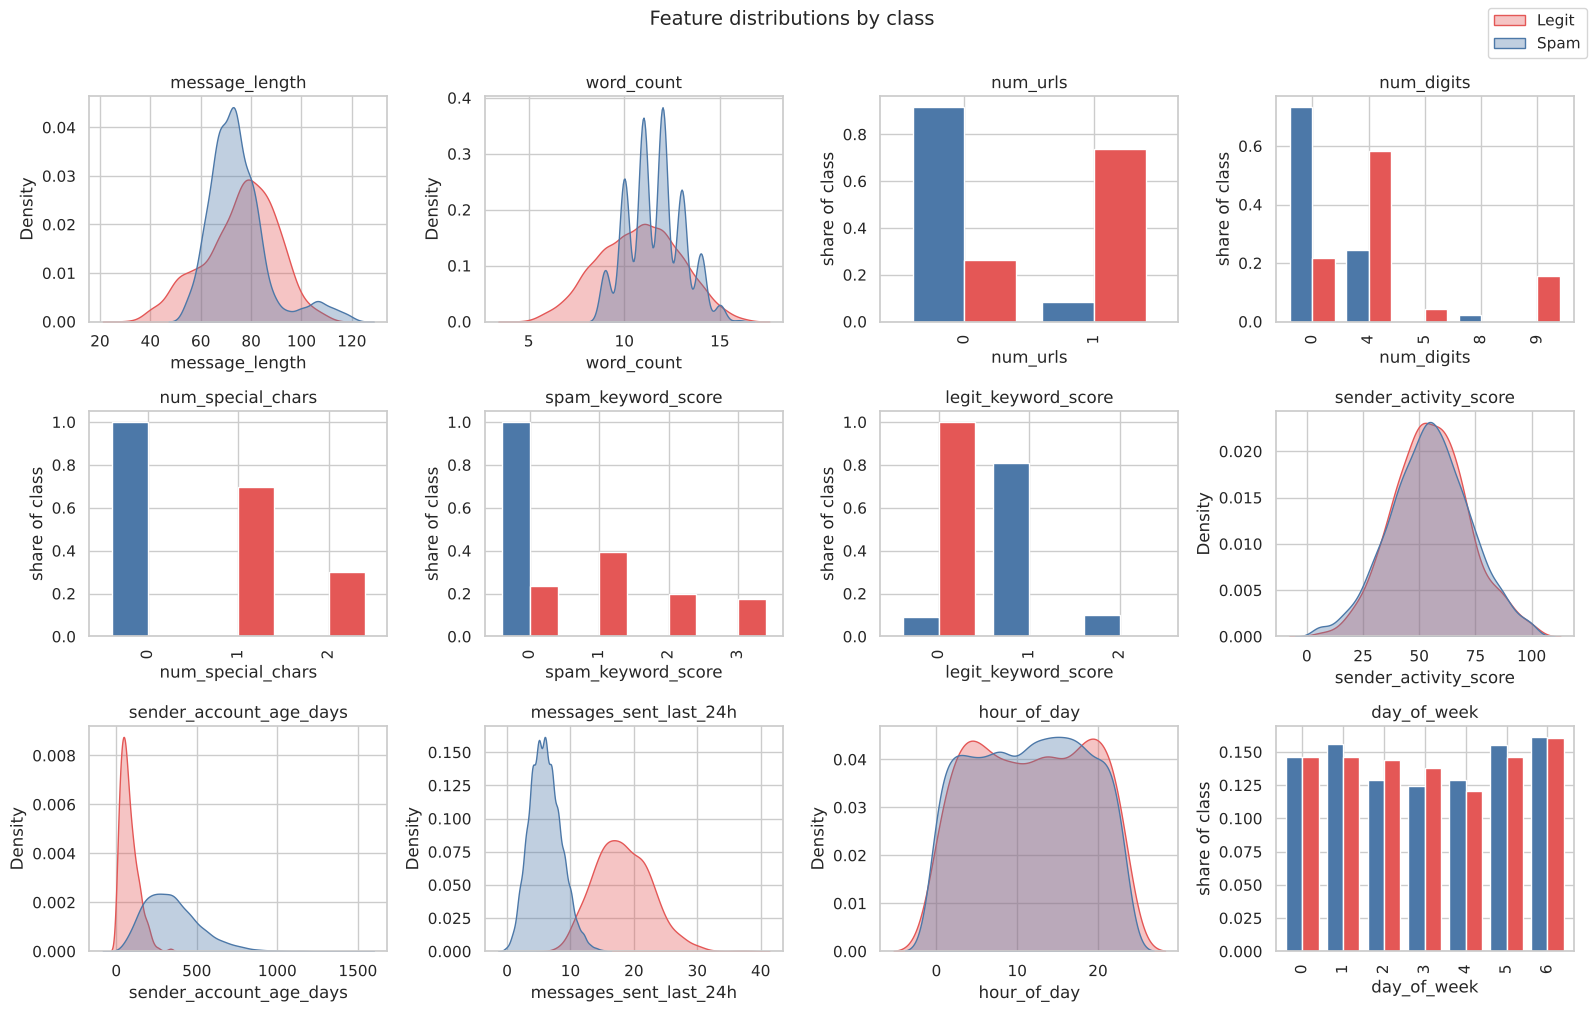

In [4]:
num_cols = ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score',
            'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h',
            'hour_of_day', 'day_of_week']
summary = df.groupby('spam_label')[num_cols].mean().T.rename(columns={0: 'legit mean', 1: 'spam mean'})
summary['ratio spam/legit'] = (summary['spam mean'] / summary['legit mean'].replace(0, np.nan)).round(2)
display(summary.round(2))

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), num_cols):
    if df[c].nunique() <= 10:
        ct = pd.crosstab(df[c], df.spam_label, normalize='columns')
        ct.plot(kind='bar', ax=ax, color=['#4C78A8', '#E45756'], width=0.8, legend=False)
        ax.set_ylabel('share of class')
    else:
        sns.kdeplot(data=df, x=c, hue='spam_label', common_norm=False, fill=True, alpha=.35, ax=ax,
                    palette=['#4C78A8', '#E45756'], legend=False)
    ax.set_title(c)
fig.legend(['Legit', 'Spam'], loc='upper right')
fig.suptitle('Feature distributions by class', y=1.01, fontsize=14)
savefig('02_feature_distributions')

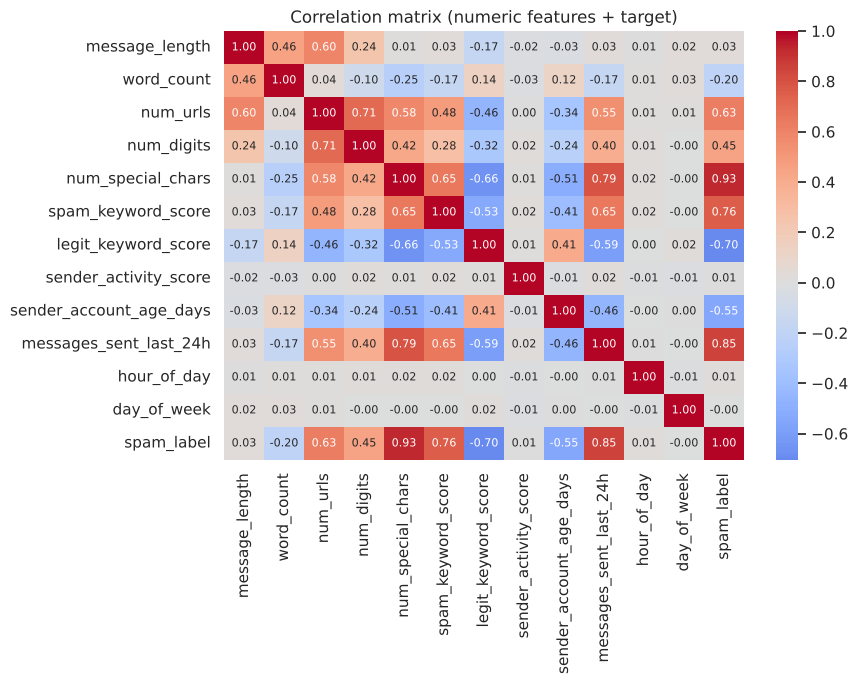

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols + ['spam_label']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation matrix (numeric features + target)')
savefig('03_correlation_heatmap')

**Interpretation.** Seven features separate the classes. Spam has far more URLs (0.74 vs 0.08 per message), digits (3.96 vs 1.16), special characters (1.30 vs 0.00), spam keywords (1.32 vs 0.00), messages sent in 24 h (18.3 vs 6.0) and much younger accounts (79 vs 347 days). Legitimate messages are the only ones with legit keywords (1.01 vs 0.00). Message length, word count, sender activity score, hour of day and day of week are almost identical between classes (ratios near 1), so they carry little signal on their own.

### Data caveat: a single feature separates the classes
The table above shows `num_special_chars` is 0 for legitimate messages and positive for spam. Before modelling, we check how far a trivial one-line rule gets, because this sets expectations for every model that follows.

In [6]:
rule = (df.num_special_chars > 0).astype(int)
print('Rule: "spam if num_special_chars > 0"')
print(pd.crosstab(df.spam_label.rename('true label'), rule.rename('rule prediction')))
print('Rule accuracy: %.4f' % (rule == df.spam_label).mean())
print('\nLegit messages with special chars: %d | Spam messages without special chars: %d' % (((df.spam_label == 0) & (rule == 1)).sum(), ((df.spam_label == 1) & (rule == 0)).sum()))
print('Spam messages with NO spam keyword (so keywords alone would miss them): %d of %d' % (((df.spam_label == 1) & (df.spam_keyword_score == 0)).sum(), df.spam_label.sum()))

Rule: "spam if num_special_chars > 0"
rule prediction     0    1
true label                
0                4227    0
1                   0  973
Rule accuracy: 1.0000

Legit messages with special chars: 0 | Spam messages without special chars: 0
Spam messages with NO spam keyword (so keywords alone would miss them): 228 of 973


**Interpretation.** This is the most important caveat of the project. Every spam message has at least one special character and no legitimate message has any, so one threshold on one feature classifies all 5,200 messages correctly. The data therefore looks synthetic and cleanly separable. Expect near-perfect scores from every reasonable model; they show that the models work, not that real-world spam filtering is this easy. Differences between models have to be found in robustness and behaviour (Parts C, D, F), not in headline accuracy. (Spam keywords alone are not enough: 228 spam messages contain none.)

### Task 6: input features and target variable

* **Target:** `spam_label` (1 = spam, 0 = legitimate).
* **Input features (12):** message length, word count, number of URLs, digits and special characters, spam / legit keyword scores (keyword frequency), sender activity score, account age, messages sent in the last 24 h, hour of day, day of week (time-based).
* **Excluded:** `message_id` (identifier, no signal), `message_text` (raw text; the assignment works on the engineered numeric features, and its signal is already summarised in the keyword/URL/digit counts) and `timestamp` (its information is already in `hour_of_day` and `day_of_week`).

In [7]:
FEATURES = num_cols
TARGET = 'spam_label'
X = df[FEATURES]
y = df[TARGET]
print(f'{len(FEATURES)} input features:', FEATURES)
print('Target:', TARGET)

12 input features: ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Target: spam_label


### Tasks 7-8: preprocessing and train/test split

Decisions:
1. **Missing values** (`sender_activity_score`, `sender_account_age_days`, `messages_sent_last_24h`, about 2-3% each) are imputed with the **median** (robust to the right-skewed account age and message counts).
2. **Scaling:** `StandardScaler` for KNN and SVM (distance / margin based, so features on large scales such as account age would otherwise dominate). Naive Bayes is scale-invariant and uses the imputed raw values so its parameters stay interpretable.
3. **Split first, then fit the preprocessing on the training set only**, which avoids data leakage. An **80/20 stratified split** keeps the 18.7% spam share in both sets.
4. All preprocessing lives inside scikit-learn `Pipeline`s, so cross-validation also never leaks test folds.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape}  spam share {y_train.mean():.3%}')
print(f'Test : {X_test.shape}  spam share {y_test.mean():.3%}')

imputer = SimpleImputer(strategy='median').fit(X_train)           # fitted on train only
print('\nMedians used for imputation:', dict(zip(FEATURES, imputer.statistics_)) if False else
      dict(X_train.median()[['sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h']].round(1)))

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=FEATURES, index=X_test.index)

scaler = StandardScaler().fit(X_train_imp)
X_train_s = scaler.transform(X_train_imp)
X_test_s = scaler.transform(X_test_imp)

before = X_train_imp[['sender_account_age_days', 'messages_sent_last_24h', 'num_urls']].agg(['mean', 'std']).round(2)
after = pd.DataFrame(X_train_s, columns=FEATURES)[['sender_account_age_days', 'messages_sent_last_24h', 'num_urls']].agg(['mean', 'std']).round(2)
print('\nBefore scaling:'); display(before)
print('After scaling (train):'); display(after)

def make_pipe(model, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale: steps.append(('scale', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (4160, 12)  spam share 18.702%
Test : (1040, 12)  spam share 18.750%

Medians used for imputation: {'sender_activity_score': np.float64(54.8), 'sender_account_age_days': np.float64(271.0), 'messages_sent_last_24h': np.float64(7.0)}

Before scaling:


,sender_account_age_days,messages_sent_last_24h,num_urls
mean,294.06,8.27,0.2
std,188.79,5.47,0.4


After scaling (train):


,sender_account_age_days,messages_sent_last_24h,num_urls
mean,-0.0,-0.0,0.0
std,1.0,1.0,1.0


## Part C: Baseline Model, K-Nearest Neighbors
### Task 9: baseline KNN

In [9]:
def evaluate(y_true, y_pred, y_score=None):
    out = {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred, zero_division=0),
           'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred)}
    if y_score is not None:
        out['ROC-AUC'] = roc_auc_score(y_true, y_score)
        out['PR-AUC'] = average_precision_score(y_true, y_score)
    return out

knn_base = make_pipe(KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
pred = knn_base.predict(X_test)
print('Baseline KNN (K=5, Euclidean, scaled)')
display(pd.DataFrame([evaluate(y_test, pred, knn_base.predict_proba(X_test)[:, 1])], index=['KNN K=5']).round(4))
print(classification_report(y_test, pred, target_names=['legit', 'spam'], digits=4))

Baseline KNN (K=5, Euclidean, scaled)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
KNN K=5,1.0,1.0,1.0,1.0,1.0,1.0


              precision    recall  f1-score   support

       legit     1.0000    1.0000    1.0000       845
        spam     1.0000    1.0000    1.0000       195

    accuracy                         1.0000      1040
   macro avg     1.0000    1.0000    1.0000      1040
weighted avg     1.0000    1.0000    1.0000      1040



### Task 10: experiment with different values of K
Odd K from 1 to 41, scored by 5-fold stratified cross-validation on the **training set only** (the test set stays untouched for the final comparison).

Best K by CV F1: 1


,cv_accuracy,cv_f1,cv_f1_std,train_f1
K,,,,
1,1.0000,1.0000,0.0000,1.0000
3,0.9998,0.9994,0.0013,1.0000
5,0.9998,0.9994,0.0013,0.9998
7,0.9998,0.9994,0.0013,0.9998
9,0.9998,0.9994,0.0013,0.9994
11,0.9995,0.9987,0.0016,0.9994
15,0.9995,0.9987,0.0016,0.9992
21,0.9990,0.9974,0.0013,0.9982
31,0.9990,0.9974,0.0013,0.9974


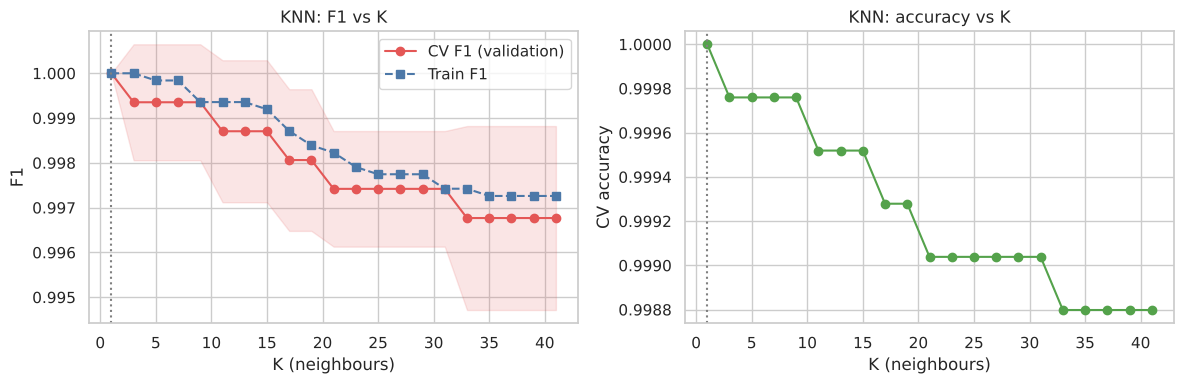

In [10]:
ks = list(range(1, 42, 2))
rows = []
for k in ks:
    pipe = make_pipe(KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'], return_train_score=True)
    rows.append({'K': k, 'cv_accuracy': r['test_accuracy'].mean(), 'cv_f1': r['test_f1'].mean(), 'cv_f1_std': r['test_f1'].std(),
                 'train_f1': r['train_f1'].mean()})
k_df = pd.DataFrame(rows).set_index('K')
best_k = int(k_df.cv_f1.idxmax())
print('Best K by CV F1:', best_k)
display(k_df.loc[[1, 3, 5, 7, 9, 11, 15, 21, 31, 41]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_df.index, k_df.cv_f1, 'o-', label='CV F1 (validation)', color='#E45756')
ax[0].plot(k_df.index, k_df.train_f1, 's--', label='Train F1', color='#4C78A8')
ax[0].fill_between(k_df.index, k_df.cv_f1 - k_df.cv_f1_std, k_df.cv_f1 + k_df.cv_f1_std, color='#E45756', alpha=.15)
ax[0].axvline(best_k, color='gray', ls=':'); ax[0].set_xlabel('K (neighbours)'); ax[0].set_ylabel('F1'); ax[0].legend(); ax[0].set_title('KNN: F1 vs K')
ax[1].plot(k_df.index, k_df.cv_accuracy, 'o-', color='#54A24B'); ax[1].axvline(best_k, color='gray', ls=':')
ax[1].set_xlabel('K (neighbours)'); ax[1].set_ylabel('CV accuracy'); ax[1].set_title('KNN: accuracy vs K')
savefig('04_knn_k_sweep')

**Interpretation.** Validation F1 is 1.000 at K=1 and stays above 0.996 all the way to K=41, so K barely matters on this clean data; very large K slowly loses a few minority-class (spam) points to the majority vote. Train F1 is trivially 1.0 at K=1 because each training point is its own nearest neighbour. K=1 wins the cross-validation here, but it is also the most sensitive to mislabeled neighbours, which the label-noise experiment in Part F confirms.

### Task 11: how distance metrics affect predictions
At the best K, we compare metrics and neighbour weighting, and show why scaling matters for a distance-based model.

,metric,weights,cv_F1,cv_precision,cv_recall,test_F1,test_accuracy
0,euclidean,uniform,1.0000,1.0000,1.0000,1.0000,1.0000
1,euclidean,distance,1.0000,1.0000,1.0000,1.0000,1.0000
2,manhattan,uniform,1.0000,1.0000,1.0000,1.0000,1.0000
3,manhattan,distance,1.0000,1.0000,1.0000,1.0000,1.0000
4,chebyshev,uniform,0.9994,1.0000,0.9987,0.9974,0.9990
5,chebyshev,distance,0.9994,1.0000,0.9987,0.9974,0.9990
6,minkowski p=3,uniform,1.0000,1.0000,1.0000,1.0000,1.0000
7,minkowski p=3,distance,1.0000,1.0000,1.0000,1.0000,1.0000
8,cosine,uniform,1.0000,1.0000,1.0000,1.0000,1.0000
9,cosine,distance,1.0000,1.0000,1.0000,1.0000,1.0000


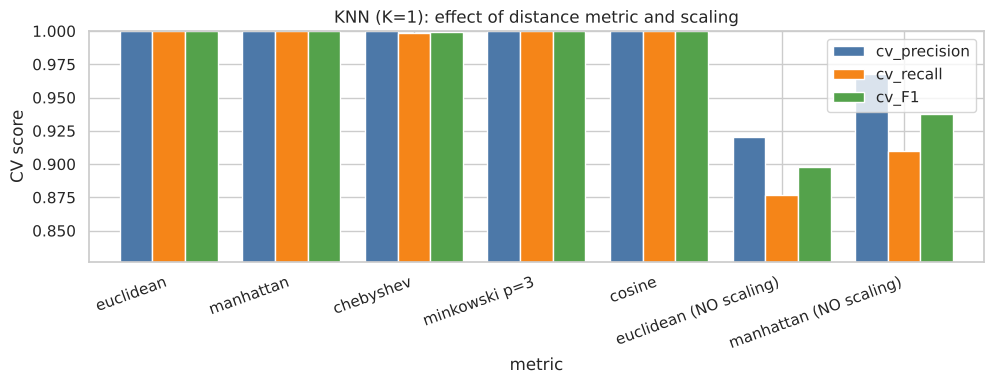

In [11]:
metrics = {'euclidean': dict(metric='euclidean'), 'manhattan': dict(metric='manhattan'), 'chebyshev': dict(metric='chebyshev'),
           'minkowski p=3': dict(metric='minkowski', p=3), 'cosine': dict(metric='cosine', algorithm='brute')}
rows = []
for name, kw in metrics.items():
    for w in ['uniform', 'distance']:
        pipe = make_pipe(KNeighborsClassifier(n_neighbors=best_k, weights=w, **kw))
        cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])
        pipe.fit(X_train, y_train); p = pipe.predict(X_test)
        rows.append({'metric': name, 'weights': w, 'cv_F1': cvr['test_f1'].mean(), 'cv_precision': cvr['test_precision'].mean(),
                     'cv_recall': cvr['test_recall'].mean(), 'test_F1': f1_score(y_test, p), 'test_accuracy': accuracy_score(y_test, p)})
# unscaled comparison
for name in ['euclidean', 'manhattan']:
    pipe = make_pipe(KNeighborsClassifier(n_neighbors=best_k, metric=name), scale=False)
    cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['precision', 'recall', 'f1'])
    pipe.fit(X_train, y_train); p = pipe.predict(X_test)
    rows.append({'metric': name + ' (NO scaling)', 'weights': 'uniform', 'cv_F1': cvr['test_f1'].mean(), 'cv_precision': cvr['test_precision'].mean(),
                 'cv_recall': cvr['test_recall'].mean(), 'test_F1': f1_score(y_test, p), 'test_accuracy': accuracy_score(y_test, p)})
metric_df = pd.DataFrame(rows)
display(metric_df.round(4))

plot_df = metric_df[metric_df.weights == 'uniform'].set_index('metric')[['cv_precision', 'cv_recall', 'cv_F1']]
ax = plot_df.plot(kind='bar', figsize=(10, 4), width=.8, color=['#4C78A8', '#F58518', '#54A24B'])
ax.set_ylim(max(0, plot_df.values.min() - .05), 1.0); ax.set_ylabel('CV score'); ax.set_title(f'KNN (K={best_k}): effect of distance metric and scaling')
plt.xticks(rotation=20, ha='right')
savefig('05_knn_distance_metrics')

**Interpretation.** Euclidean, Manhattan, Minkowski (p=3) and cosine all reach CV F1 = 1.000, while Chebyshev is slightly worse (0.9994, one test error) because it looks only at the single largest coordinate difference and ignores the rest. The much bigger effect is scaling: without it, Euclidean KNN drops to CV F1 0.898 and Manhattan to 0.938, because account age (standard deviation about 189) swamps small-range features such as special characters and keyword scores. Manhattan suffers less than Euclidean because it does not square the large differences.

### Task 12: where does KNN misclassify messages?

In [12]:
best_metric_row = metric_df[~metric_df.metric.str.contains('NO')].sort_values('cv_F1', ascending=False).iloc[0]
print('Chosen KNN configuration -> K=%d, metric=%s, weights=%s' % (best_k, best_metric_row.metric, best_metric_row.weights))
kw = metrics[best_metric_row.metric]
knn = make_pipe(KNeighborsClassifier(n_neighbors=best_k, weights=best_metric_row.weights, **kw)).fit(X_train, y_train)
knn_pred = knn.predict(X_test); knn_score = knn.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, knn_pred)
print('Confusion matrix [[TN FP],[FN TP]]:\n', cm)
test_view = df.loc[X_test.index].assign(pred=knn_pred, score=knn_score)
errs = test_view[test_view.pred != test_view.spam_label]
fp = errs[errs.spam_label == 0]; fn = errs[errs.spam_label == 1]
print(f'\nFalse positives (legit flagged as spam): {len(fp)}   False negatives (spam missed): {len(fn)}')

cols = ['message_text', 'spam_keyword_score', 'num_urls', 'num_special_chars', 'messages_sent_last_24h', 'sender_account_age_days', 'score']
print('\n--- Missed spam (false negatives) ---'); display(fn[cols].head(10))
print('--- Legit flagged as spam (false positives) ---'); display(fp[cols].head(10))

Chosen KNN configuration -> K=1, metric=euclidean, weights=uniform
Confusion matrix [[TN FP],[FN TP]]:
 [[845   0]
 [  0 195]]

False positives (legit flagged as spam): 0   False negatives (spam missed): 0

--- Missed spam (false negatives) ---


,message_text,spam_keyword_score,num_urls,num_special_chars,messages_sent_last_24h,sender_account_age_days,score


--- Legit flagged as spam (false positives) ---


,message_text,spam_keyword_score,num_urls,num_special_chars,messages_sent_last_24h,sender_account_age_days,score


,,spam_keyword_score,num_urls,num_special_chars,num_digits,messages_sent_last_24h,sender_account_age_days,sender_activity_score
spam_label,correct,,,,,,,
0,True,0.00,0.10,0.00,1.23,5.95,357.32,54.17
1,True,1.22,0.72,1.29,4.03,18.63,75.81,59.19


Missed spam with spam_keyword_score == 0: 0 of 0 misses
Recall on spam WITH keywords: 1.000 | spam WITHOUT keywords: 1.000


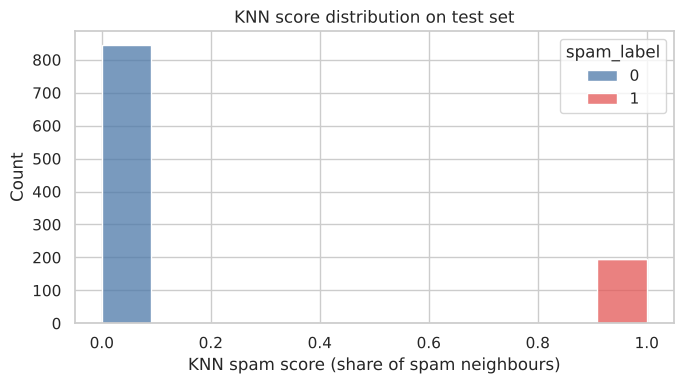

In [13]:
# What do misclassified messages have in common?
test_view['correct'] = test_view.pred == test_view.spam_label
prof = test_view.groupby(['spam_label', 'correct'])[['spam_keyword_score', 'num_urls', 'num_special_chars', 'num_digits', 'messages_sent_last_24h',
                                                       'sender_account_age_days', 'sender_activity_score']].mean().round(2)
display(prof)
spam_t = test_view[test_view.spam_label == 1]
print('Missed spam with spam_keyword_score == 0: %d of %d misses' % ((fn.spam_keyword_score == 0).sum(), len(fn)))
print('Recall on spam WITH keywords: %.3f | spam WITHOUT keywords: %.3f' %
      (spam_t[spam_t.spam_keyword_score > 0].correct.mean(), spam_t[spam_t.spam_keyword_score == 0].correct.mean()))

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=test_view, x='score', hue='spam_label', bins=11, multiple='stack', palette=['#4C78A8', '#E45756'], ax=ax)
ax.set_xlabel('KNN spam score (share of spam neighbours)'); ax.set_title('KNN score distribution on test set')
savefig('06_knn_score_distribution')

The tuned KNN makes **no** errors on this test set, so there is nothing to dissect yet. To answer Task 12 properly we stress-test KNN with configurations that are *known to be weaker* (no scaling, a very large K, a poor metric) and study the messages they get wrong.

In [14]:
stress = {'K=5, Euclidean, NO scaling': make_pipe(KNeighborsClassifier(n_neighbors=5), scale=False),
          'K=41, Euclidean, scaled': make_pipe(KNeighborsClassifier(n_neighbors=41)),
          'K=1, Chebyshev, scaled': make_pipe(KNeighborsClassifier(n_neighbors=1, metric='chebyshev'))}
srows, err_sets = [], {}
for name, pipe in stress.items():
    pipe.fit(X_train, y_train); p = pipe.predict(X_test)
    tv = df.loc[X_test.index].assign(pred=p)
    e = tv[tv.pred != tv.spam_label]; err_sets[name] = e
    srows.append({'configuration': name, 'errors': len(e), 'false positives': int((e.spam_label == 0).sum()), 'false negatives': int((e.spam_label == 1).sum()),
                  'accuracy': 1 - len(e) / len(tv)})
display(pd.DataFrame(srows).set_index('configuration').round(4))

worst = max(err_sets, key=lambda k: len(err_sets[k])); e = err_sets[worst]
print(f'Misclassified messages under the weakest configuration ({worst}):')
display(e[['message_text', 'spam_label', 'pred', 'spam_keyword_score', 'num_urls', 'num_special_chars', 'messages_sent_last_24h', 'sender_account_age_days']].head(12))

compare_cols = ['sender_account_age_days', 'messages_sent_last_24h', 'sender_activity_score', 'num_digits', 'num_urls', 'spam_keyword_score', 'num_special_chars']
profile = pd.concat({'all test messages': df.loc[X_test.index, compare_cols].mean(), 'misclassified': e[compare_cols].mean(),
                     'misclassified spam (FN)': e[e.spam_label == 1][compare_cols].mean(), 'misclassified legit (FP)': e[e.spam_label == 0][compare_cols].mean()}, axis=1)
display(profile.round(2))
print('Share of FN that carry a spam keyword: %.0f%% | share of FP with URL: %.0f%%' % (100 * (e[e.spam_label == 1].spam_keyword_score > 0).mean() if (e.spam_label == 1).any() else float('nan'),
      100 * (e[e.spam_label == 0].num_urls > 0).mean() if (e.spam_label == 0).any() else float('nan')))

,errors,false positives,false negatives,accuracy
configuration,,,,
"K=5, Euclidean, NO scaling",33,9,24,0.9683
"K=41, Euclidean, scaled",2,0,2,0.9981
"K=1, Chebyshev, scaled",1,0,1,0.9990


Misclassified messages under the weakest configuration (K=5, Euclidean, NO scaling):


,message_text,spam_label,pred,spam_keyword_score,num_urls,num_special_chars,messages_sent_last_24h,sender_account_age_days
1436,Payment received successfully for your subscription. the updated proposal. Appreciate it.,0,1,0,0,0,7.0,44.0
2292,You've been selected for a cash prize of a brand new phone limited time!,1,0,2,0,1,16.0,264.0
4511,"You've been selected for a cash prize of ₹50,000 now! https://tinyurl.com/6902",1,0,2,1,1,13.0,198.0
292,You are eligible for a refund of instant cashback now! http://promo.example/9994,1,0,1,1,1,29.0,188.0
3594,Limited offer! Get free gift cards limited time! http://bit.ly/1563,1,0,2,1,2,16.0,97.0
1154,You are eligible for a refund of instant cashback now! http://promo.example/7784,1,0,1,1,1,11.0,152.0
3878,URGENT: Claim your reward now exclusive bonus now!,1,0,3,0,1,29.0,337.0
1059,Earn money from home instantly exclusive bonus ASAP! http://promo.example/5973,1,0,1,1,1,17.0,NaN
4750,Get rich quick with this simple trick a brand new phone limited time! http://promo.example/1346,1,0,0,1,1,NaN,NaN
2851,Could you review the document and share feedback? the quarterly review. Appreciate it.,0,1,0,0,0,5.0,64.0


,all test messages,misclassified,misclassified spam (FN),misclassified legit (FP)
sender_account_age_days,304.93,147.31,182.75,68.56
messages_sent_last_24h,8.26,14.69,17.80,7.78
sender_activity_score,55.10,58.32,58.05,59.10
num_digits,1.75,3.42,4.04,1.78
num_urls,0.22,0.58,0.75,0.11
spam_keyword_score,0.23,0.91,1.25,0.00
num_special_chars,0.24,0.91,1.25,0.00


Share of FN that carry a spam keyword: 75% | share of FP with URL: 11%


**Interpretation.** Stress tests show where KNN breaks. Without scaling it makes 33 errors on 1,040 test messages (24 missed spam, 9 false alarms). The missed spam are obviously spammy in text ("cash prize", "instant cashback") and 75% carry a spam keyword, but they come from older accounts (about 183 days vs 79 on average for spam) and the unscaled distance is dominated by account age, so they land among legitimate neighbours. The false alarms are legitimate messages from very new accounts (about 69 days), which look like spam for the same reason. With K=41 or the Chebyshev metric the only errors are 1-2 missed spam, i.e. borderline points near the class boundary.

## Part D: Support Vector Machine Classifier
### Task 13: linear, RBF and polynomial kernels
First with default hyper-parameters (C=1), then tuned by grid search (5-fold CV on the training set, F1).

In [15]:
kernels = {'Linear': SVC(kernel='linear', C=1.0), 'RBF': SVC(kernel='rbf', C=1.0, gamma='scale'),
           'Polynomial (deg 3)': SVC(kernel='poly', degree=3, C=1.0, gamma='scale')}
rows = []
for name, m in kernels.items():
    pipe = make_pipe(m)
    t0 = time.time(); pipe.fit(X_train, y_train); tt = time.time() - t0
    p = pipe.predict(X_test); s = pipe.decision_function(X_test)
    r = evaluate(y_test, p, s); r['Train time (s)'] = tt; r['# support vectors'] = int(pipe.named_steps['model'].n_support_.sum())
    rows.append(pd.Series(r, name=name + ' (default)'))
svm_default = pd.DataFrame(rows)
display(svm_default.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s),# support vectors
Linear (default),1.0,1.0,1.0,1.0,1.0,1.0,0.0174,10.0
RBF (default),1.0,1.0,1.0,1.0,1.0,1.0,0.0312,139.0
Polynomial (deg 3) (default),1.0,1.0,1.0,1.0,1.0,1.0,0.0203,67.0


In [16]:
grids = {
    'Linear': (SVC(kernel='linear'), {'model__C': [0.01, 0.1, 1, 10, 100]}),
    'RBF': (SVC(kernel='rbf'), {'model__C': [0.1, 1, 10, 100], 'model__gamma': ['scale', 0.003, 0.01, 0.03, 0.1, 0.3]}),
    'Polynomial': (SVC(kernel='poly'), {'model__C': [0.1, 1, 10], 'model__degree': [2, 3, 4], 'model__gamma': ['scale', 0.03, 0.1]}),
}
svm_tuned, tune_rows = {}, []
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=cv, scoring='f1', n_jobs=-1).fit(X_train, y_train)
    svm_tuned[name] = gs.best_estimator_
    p = gs.predict(X_test); s = gs.decision_function(X_test)
    r = evaluate(y_test, p, s); r.update({'best CV F1': gs.best_score_, 'best params': {k.split('__')[1]: v for k, v in gs.best_params_.items()},
                                          '# SV': int(gs.best_estimator_.named_steps['model'].n_support_.sum())})
    tune_rows.append(pd.Series(r, name=name + ' (tuned)'))
svm_tuned_df = pd.DataFrame(tune_rows)
display(svm_tuned_df)
best_svm_name = svm_tuned_df['best CV F1'].idxmax().replace(' (tuned)', '')
print('Best SVM kernel by CV F1:', best_svm_name)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,best CV F1,best params,# SV
Linear (tuned),1.0,1.0,1.0,1.0,1.0,1.0,1.0,{'C': 0.01},82
RBF (tuned),1.0,1.0,1.0,1.0,1.0,1.0,1.0,"{'C': 0.1, 'gamma': 'scale'}",301
Polynomial (tuned),1.0,1.0,1.0,1.0,1.0,1.0,1.0,"{'C': 1, 'degree': 2, 'gamma': 'scale'}",79


Best SVM kernel by CV F1: Linear


### Task 14: margin separation and support vectors

,margin width 2/||w||,# SV (legit),# SV (spam),SV share of train,inside margin |f|<1,train errors
C,,,,,,
0.001,3.3902,214,212,0.1024,422,1
0.010,2.3820,42,40,0.0197,77,0
0.100,1.9604,9,9,0.0043,12,0
1.000,1.8913,5,5,0.0024,3,0
10.000,1.8913,5,5,0.0024,3,0
100.000,1.8913,5,5,0.0024,3,0


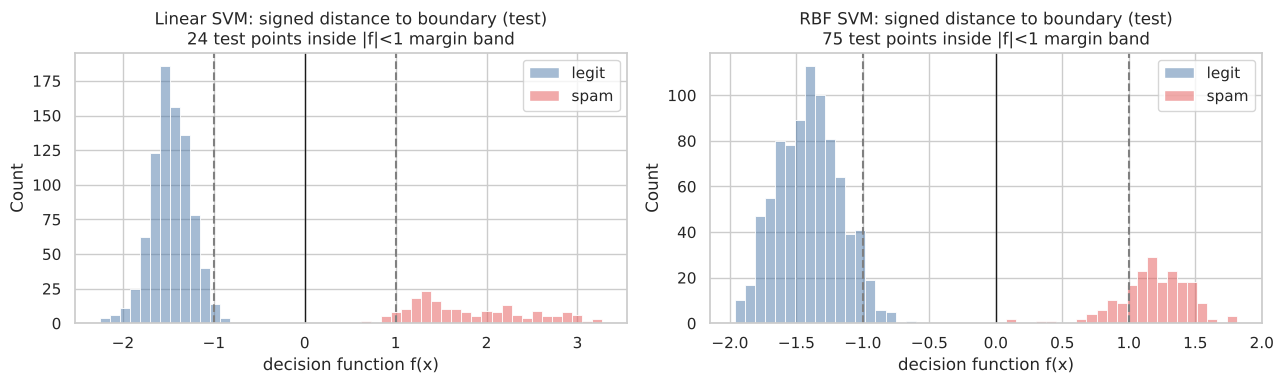

In [17]:
# (a) Support vectors per class, and how C controls the margin (linear kernel, scaled data)
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel='linear', C=C).fit(X_train_s, y_train)
    w = m.coef_.ravel(); f = m.decision_function(X_train_s)
    rows.append({'C': C, 'margin width 2/||w||': 2 / np.linalg.norm(w), '# SV (legit)': m.n_support_[0], '# SV (spam)': m.n_support_[1],
                 'SV share of train': m.n_support_.sum() / len(X_train_s), 'inside margin |f|<1': int((np.abs(f) < 1).sum()),
                 'train errors': int((m.predict(X_train_s) != y_train).sum())})
c_df = pd.DataFrame(rows).set_index('C'); display(c_df.round(4))

# (b) distance of test points to the decision boundary for the tuned models
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, ['Linear', 'RBF']):
    s = svm_tuned[name].decision_function(X_test)
    sns.histplot(x=s, hue=y_test.map({0: 'legit', 1: 'spam'}).values, bins=50, palette={'legit': '#4C78A8', 'spam': '#E45756'}, ax=ax)
    ax.axvline(0, color='k', lw=1); ax.axvline(-1, color='gray', ls='--'); ax.axvline(1, color='gray', ls='--')
    ax.set_title(f'{name} SVM: signed distance to boundary (test)\n{(np.abs(s) < 1).sum()} test points inside |f|<1 margin band'); ax.set_xlabel('decision function f(x)')
savefig('07_svm_margin_distribution')

Variance explained by 2 PCs: 48.8%


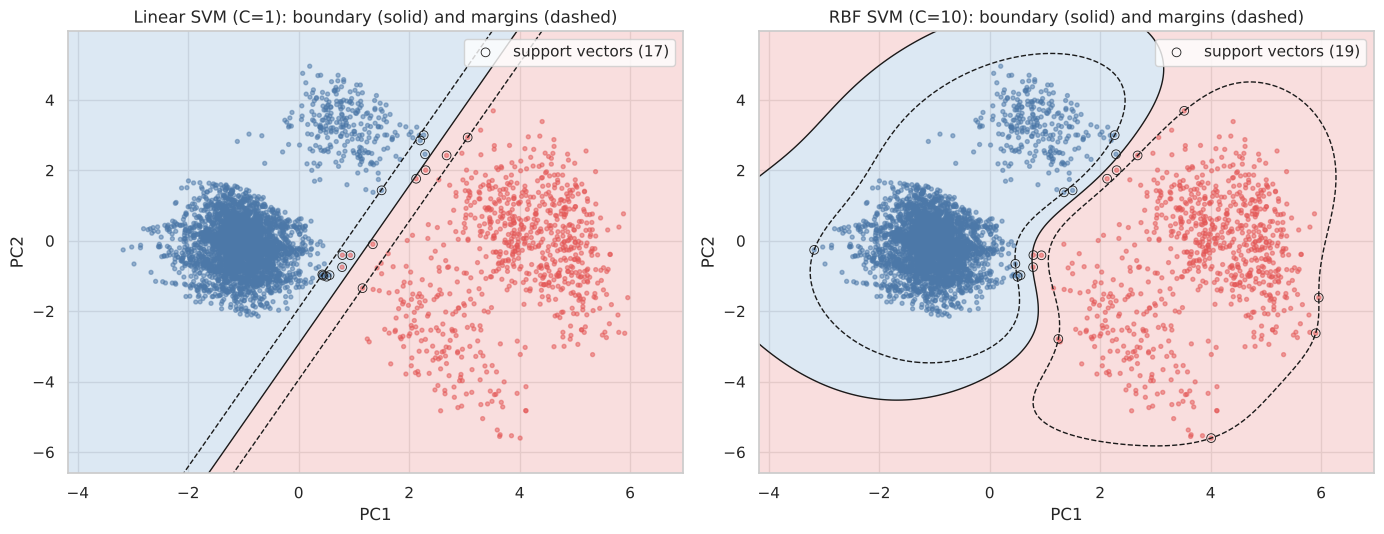

In [18]:
# (c) 2-D visualisation: project to the first two principal components and refit SVMs (for display only)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_s)
Z_train, Z_test = pca.transform(X_train_s), pca.transform(X_test_s)
print('Variance explained by 2 PCs: %.1f%%' % (100 * pca.explained_variance_ratio_.sum()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
gx, gy = np.meshgrid(np.linspace(Z_train[:, 0].min() - 1, Z_train[:, 0].max() + 1, 300), np.linspace(Z_train[:, 1].min() - 1, Z_train[:, 1].max() + 1, 300))
for ax, (name, m) in zip(axes, {'Linear SVM (C=1)': SVC(kernel='linear', C=1), 'RBF SVM (C=10)': SVC(kernel='rbf', C=10, gamma='scale')}.items()):
    m.fit(Z_train, y_train)
    zz = m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, zz, levels=[-100, 0, 100], colors=['#C6D9EC', '#F6C9C8'], alpha=.6)
    ax.contour(gx, gy, zz, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=1)
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train.map({0: '#4C78A8', 1: '#E45756'}), s=8, alpha=.5)
    ax.scatter(*m.support_vectors_.T, s=40, facecolors='none', edgecolors='k', linewidths=.6, label=f'support vectors ({len(m.support_vectors_)})')
    ax.set_title(f'{name}: boundary (solid) and margins (dashed)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(loc='upper right')
savefig('08_svm_decision_boundary_pca')

**Interpretation.** The table shows the soft-margin trade-off: with a tiny C=0.001 the margin is wide (width 3.39) and 426 points (10.2% of training data) are support vectors, 422 of them inside the margin band. From C=1 upward nothing changes: the margin settles at 1.89 with only 10 support vectors and no training errors, which means the classes are linearly separable and the hard-margin solution has been reached. The 2-D PCA picture keeps only 48.8% of the variance, so overlap that appears there is a projection effect rather than real class overlap.

### Task 15: SVM vs KNN

In [19]:
svm_best = svm_tuned[best_svm_name]
svm_pred = svm_best.predict(X_test); svm_score = svm_best.decision_function(X_test)
t0 = time.time(); svm_best.predict(X_test); svm_pt = time.time() - t0
t0 = time.time(); knn.predict(X_test); knn_pt = time.time() - t0
cmp = pd.DataFrame([evaluate(y_test, knn_pred, knn_score), evaluate(y_test, svm_pred, svm_score)], index=[f'KNN (K={best_k})', f'SVM ({best_svm_name})'])
cmp['Predict time (s)'] = [knn_pt, svm_pt]
display(cmp.round(4))
print('Errors  KNN: %d   SVM: %d   (of %d test messages)' % ((knn_pred != y_test).sum(), (svm_pred != y_test).sum(), len(y_test)))
both = ((knn_pred != y_test) & (svm_pred != y_test)).sum()
print('Misclassified by both: %d | only KNN: %d | only SVM: %d' % (both, ((knn_pred != y_test) & (svm_pred == y_test)).sum(), ((knn_pred == y_test) & (svm_pred != y_test)).sum()))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Predict time (s)
KNN (K=1),1.0,1.0,1.0,1.0,1.0,1.0,0.0248
SVM (Linear),1.0,1.0,1.0,1.0,1.0,1.0,0.0039


Errors  KNN: 0   SVM: 0   (of 1040 test messages)
Misclassified by both: 0 | only KNN: 0 | only SVM: 0


**Interpretation.** Both reach 1.000 on every metric with zero errors, so accuracy cannot separate them. The practical differences are elsewhere: the tuned linear SVM stores only 82 support vectors and predicts several times faster than KNN, which must keep and search all 4,160 training messages. Grid search selected linear C=0.01 (RBF and polynomial also scored CV F1 = 1.0, so the choice among tied kernels is arbitrary and the simplest, the linear kernel, is the natural pick); the non-linear kernels bring no gain because the problem is linearly separable.

## Part E: Naive Bayes Classifier & Probability
### Task 16: Gaussian Naive Bayes
Features are the imputed, **unscaled** values (Naive Bayes is scale-invariant, and this keeps the learned means and variances interpretable).

In [20]:
nb = GaussianNB().fit(X_train_imp, y_train)
nb_pred = nb.predict(X_test_imp); nb_proba = nb.predict_proba(X_test_imp)[:, 1]
display(pd.DataFrame([evaluate(y_test, nb_pred, nb_proba)], index=['Gaussian NB']).round(4))
print(classification_report(y_test, nb_pred, target_names=['legit', 'spam'], digits=4))

params = pd.DataFrame({'mean (legit)': nb.theta_[0], 'std (legit)': np.sqrt(nb.var_[0]), 'mean (spam)': nb.theta_[1], 'std (spam)': np.sqrt(nb.var_[1])}, index=FEATURES)
print('Learned class-conditional Gaussian parameters:'); display(params.round(3))
print('Class priors  P(legit)=%.4f  P(spam)=%.4f' % tuple(nb.class_prior_))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Gaussian NB,0.999,0.9949,1.0,0.9974,1.0,1.0


              precision    recall  f1-score   support

       legit     1.0000    0.9988    0.9994       845
        spam     0.9949    1.0000    0.9974       195

    accuracy                         0.9990      1040
   macro avg     0.9974    0.9994    0.9984      1040
weighted avg     0.9990    0.9990    0.9990      1040

Learned class-conditional Gaussian parameters:


,mean (legit),std (legit),mean (spam),std (spam)
message_length,74.780,11.835,76.343,14.279
word_count,11.614,1.432,10.812,2.104
num_urls,0.080,0.271,0.744,0.436
num_digits,1.140,1.988,3.941,2.724
num_special_chars,0.000,0.006,1.306,0.461
spam_keyword_score,0.000,0.006,1.341,1.015
legit_keyword_score,1.009,0.438,0.000,0.006
sender_activity_score,54.923,17.734,54.112,16.650
sender_account_age_days,342.579,174.395,83.170,60.167
messages_sent_last_24h,6.073,2.413,17.843,4.702


Class priors  P(legit)=0.8130  P(spam)=0.1870


### Tasks 17-18: manual conditional probabilities and Bayes' theorem

**Part 1, a hand calculation with simple events.** Using training-set counts, define: *Spam* = spam label, *URL* = message has at least one URL, *KW* = spam keyword score > 0, *HV* = more than 12 messages sent in 24 h.

$$P(\text{Spam}\mid \text{URL})=\frac{P(\text{URL}\mid \text{Spam})\,P(\text{Spam})}{P(\text{URL}\mid \text{Spam})P(\text{Spam})+P(\text{URL}\mid \text{Legit})P(\text{Legit})}$$

In [21]:
tr = X_train_imp.assign(y=y_train.values)
tr['URL'] = tr.num_urls >= 1; tr['KW'] = tr.spam_keyword_score > 0; tr['HV'] = tr.messages_sent_last_24h > 12
n = len(tr); n_spam = (tr.y == 1).sum(); n_leg = (tr.y == 0).sum()
P_spam, P_leg = n_spam / n, n_leg / n
print(f'Priors: P(Spam)={n_spam}/{n}={P_spam:.4f}   P(Legit)={n_leg}/{n}={P_leg:.4f}\n')

alpha = 1  # Laplace smoothing so that no probability is exactly 0
lik = {}
for ev in ['URL', 'KW', 'HV']:
    ps = (tr.loc[tr.y == 1, ev].sum() + alpha) / (n_spam + 2 * alpha)
    pl = (tr.loc[tr.y == 0, ev].sum() + alpha) / (n_leg + 2 * alpha)
    lik[ev] = (ps, pl)
    ev_marg = ps * P_spam + pl * P_leg
    post = ps * P_spam / ev_marg
    emp = tr.loc[tr[ev], 'y'].mean()
    print(f'P({ev}|Spam)={ps:.4f}  P({ev}|Legit)={pl:.4f}  ->  Bayes P(Spam|{ev}) = {post:.4f}   (empirical: {emp:.4f})')

# naive combination of all three events vs the empirical posterior of the same combination
num_s = P_spam * np.prod([lik[e][0] for e in lik]); num_l = P_leg * np.prod([lik[e][1] for e in lik])
naive_post = num_s / (num_s + num_l)
mask = tr.URL & tr.KW & tr.HV
print(f'\nNaive-Bayes posterior P(Spam | URL, KW, HV) = {naive_post:.4f}')
print(f'Empirical     P(Spam | URL, KW, HV) = {tr.loc[mask, "y"].mean():.4f}  (n={mask.sum()} training messages)')

Priors: P(Spam)=778/4160=0.1870   P(Legit)=3382/4160=0.8130

P(URL|Spam)=0.7436  P(URL|Legit)=0.0801  ->  Bayes P(Spam|URL) = 0.6811   (empirical: 0.6820)
P(KW|Spam)=0.7808  P(KW|Legit)=0.0003  ->  Bayes P(Spam|KW) = 0.9984   (empirical: 1.0000)
P(HV|Spam)=0.8833  P(HV|Legit)=0.0092  ->  Bayes P(Spam|HV) = 0.9569   (empirical: 0.9582)

Naive-Bayes posterior P(Spam | URL, KW, HV) = 1.0000
Empirical     P(Spam | URL, KW, HV) = 1.0000  (n=396 training messages)


**Part 2, the full Gaussian Naive Bayes computed by hand.** For a message $x=(x_1,\dots,x_d)$ and class $c$:

$$\log P(c\mid x)\;\propto\;\log P(c)+\sum_{j=1}^{d}\Big[-\tfrac12\log(2\pi\sigma_{cj}^2)-\frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Big],\qquad P(c\mid x)=\frac{e^{\log P(c)+\log P(x\mid c)}}{\sum_{c'}e^{\log P(c')+\log P(x\mid c')}}$$

We apply this to three test messages (a clear spam, a clear legit message and the most uncertain one) and verify it against `predict_proba`.

In [22]:
def manual_nb(x, nb):
    """Hand-written Gaussian NB posterior using the fitted means/variances/priors."""
    log_prior = np.log(nb.class_prior_)
    per_feat = -0.5 * np.log(2 * np.pi * nb.var_) - (x - nb.theta_) ** 2 / (2 * nb.var_)     # (classes, features)
    log_joint = log_prior + per_feat.sum(axis=1)
    post = np.exp(log_joint - logsumexp(log_joint))
    return post, per_feat, log_joint

unc = np.abs(nb_proba - 0.5)
idx_spam = X_test_imp.index[(y_test.values == 1) & (nb_pred == 1)][0]
idx_leg = X_test_imp.index[(y_test.values == 0) & (nb_pred == 0)][0]
idx_unc = X_test_imp.index[np.argmin(unc)]
samples = {'Clear spam': idx_spam, 'Clear legit': idx_leg, 'Most uncertain': idx_unc}

rows = []
for label, ix in samples.items():
    x = X_test_imp.loc[ix].values.astype(float)
    post, per_feat, log_joint = manual_nb(x, nb)
    sk = nb.predict_proba(x.reshape(1, -1))[0]
    assert np.allclose(post, sk), 'manual and sklearn posteriors differ'
    print(f'=== {label} (message_id {df.loc[ix, "message_id"]}, true label {y_test.loc[ix]}) ===')
    print('Text:', df.loc[ix, 'message_text'])
    contrib = pd.DataFrame({'x': x, 'log N(x|legit)': per_feat[0], 'log N(x|spam)': per_feat[1]}, index=FEATURES)
    contrib['log-LR (spam - legit)'] = contrib['log N(x|spam)'] - contrib['log N(x|legit)']
    display(contrib.round(2))
    print(f'log prior: legit {np.log(nb.class_prior_[0]):.3f}, spam {np.log(nb.class_prior_[1]):.3f} | log joint: legit {log_joint[0]:.2f}, spam {log_joint[1]:.2f}')
    print(f'Manual posterior  P(legit)={post[0]:.6f}  P(spam)={post[1]:.6f}   |  sklearn P(spam)={sk[1]:.6f}\n')
    rows.append({'sample': label, 'true': int(y_test.loc[ix]), 'manual P(spam)': post[1], 'sklearn P(spam)': sk[1], 'predicted': int(post[1] > .5)})
manual_df = pd.DataFrame(rows).set_index('sample')

=== Clear spam (message_id 900656, true label 1) ===
Text: Earn money from home instantly a brand new phone limited time!


,x,log N(x|legit),log N(x|spam),log-LR (spam - legit)
message_length,62.0,-3.97,-4.08,-0.11
word_count,11.0,-1.37,-1.67,-0.30
num_urls,0.0,0.34,-1.54,-1.89
num_digits,0.0,-1.77,-2.97,-1.20
num_special_chars,1.0,-14027.31,-0.36,14026.94
spam_keyword_score,0.0,4.20,-1.81,-6.01
legit_keyword_score,0.0,-2.75,4.20,6.95
sender_activity_score,40.9,-4.11,-4.05,0.06
sender_account_age_days,13.0,-7.87,-5.70,2.17
messages_sent_last_24h,21.0,-20.94,-2.69,18.24


log prior: legit -0.207, spam -1.677 | log joint: legit -14071.25, spam -27.88
Manual posterior  P(legit)=0.000000  P(spam)=1.000000   |  sklearn P(spam)=1.000000

=== Clear legit (message_id 900800, true label 0) ===
Text: Your order has been shipped and will arrive by the updated proposal. Please confirm.


,x,log N(x|legit),log N(x|spam),log-LR (spam - legit)
message_length,84.0,-3.69,-3.72,-0.03
word_count,14.0,-2.67,-2.81,-0.14
num_urls,0.0,0.34,-1.54,-1.89
num_digits,0.0,-1.77,-2.97,-1.20
num_special_chars,0.0,4.20,-4.16,-8.36
spam_keyword_score,0.0,4.20,-1.81,-6.01
legit_keyword_score,1.0,-0.09,-14027.31,-14027.21
sender_activity_score,27.8,-4.96,-4.98,-0.02
sender_account_age_days,282.0,-6.14,-10.48,-4.34
messages_sent_last_24h,6.0,-1.80,-5.64,-3.84


log prior: legit -0.207, spam -1.677 | log joint: legit -17.98, spam -14072.43
Manual posterior  P(legit)=1.000000  P(spam)=0.000000   |  sklearn P(spam)=0.000000

=== Most uncertain (message_id 904392, true label 0) ===
Text: Let's catch up tomorrow regarding the timeline. 10:30 AM. Appreciate it. https://company.portal/docs/1939


,x,log N(x|legit),log N(x|spam),log-LR (spam - legit)
message_length,105.0,-6.65,-5.59,1.06
word_count,12.0,-1.31,-1.82,-0.51
num_urls,1.0,-5.37,-0.26,5.11
num_digits,8.0,-7.56,-3.03,4.53
num_special_chars,0.0,4.20,-4.16,-8.36
spam_keyword_score,0.0,4.20,-1.81,-6.01
legit_keyword_score,0.0,-2.75,4.20,6.95
sender_activity_score,66.0,-3.99,-3.99,0.00
sender_account_age_days,198.0,-6.42,-6.84,-0.41
messages_sent_last_24h,10.0,-3.12,-3.86,-0.73


log prior: legit -0.207, spam -1.677 | log joint: legit -35.75, spam -35.52
Manual posterior  P(legit)=0.442769  P(spam)=0.557231   |  sklearn P(spam)=0.557231



### Task 19: theoretical probability vs model predictions

,true,manual P(spam),sklearn P(spam),predicted
sample,,,,
Clear spam,1,1.000000,1.000000,1
Clear legit,0,0.000000,0.000000,0
Most uncertain,0,0.557231,0.557231,1


Largest |manual - sklearn| posterior difference over ALL 1040 test messages: 5.07e-17


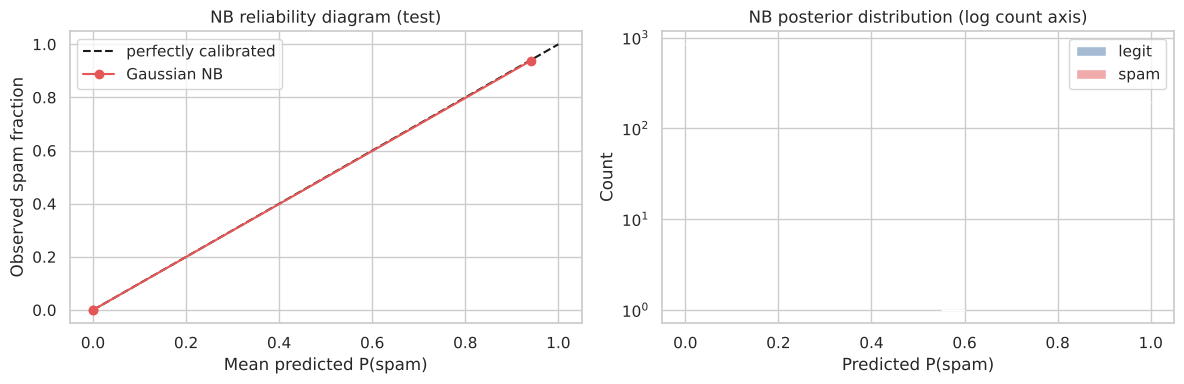

Brier score: 0.0003   | share of test messages with P(spam)<0.01 or >0.99: 99.9%


In [23]:
display(manual_df.round(6))
max_diff = max(abs(manual_nb(X_test_imp.iloc[i].values.astype(float), nb)[0][1] - nb_proba[i]) for i in range(len(X_test_imp)))
print('Largest |manual - sklearn| posterior difference over ALL %d test messages: %.2e' % (len(X_test_imp), max_diff))

# How confident (and how well calibrated) are the NB probabilities?
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
frac_pos, mean_pred = calibration_curve(y_test, nb_proba, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([0, 1], [0, 1], 'k--', label='perfectly calibrated'); ax[0].plot(mean_pred, frac_pos, 'o-', color='#E45756', label='Gaussian NB')
ax[0].set_xlabel('Mean predicted P(spam)'); ax[0].set_ylabel('Observed spam fraction'); ax[0].legend(); ax[0].set_title('NB reliability diagram (test)')
sns.histplot(x=nb_proba, hue=y_test.map({0: 'legit', 1: 'spam'}).values, bins=20, log_scale=(False, True), palette={'legit': '#4C78A8', 'spam': '#E45756'}, ax=ax[1])
ax[1].set_xlabel('Predicted P(spam)'); ax[1].set_title('NB posterior distribution (log count axis)')
savefig('09_nb_calibration')
print('Brier score: %.4f   | share of test messages with P(spam)<0.01 or >0.99: %.1f%%' % (brier_score_loss(y_test, nb_proba), 100 * np.mean((nb_proba < .01) | (nb_proba > .99))))

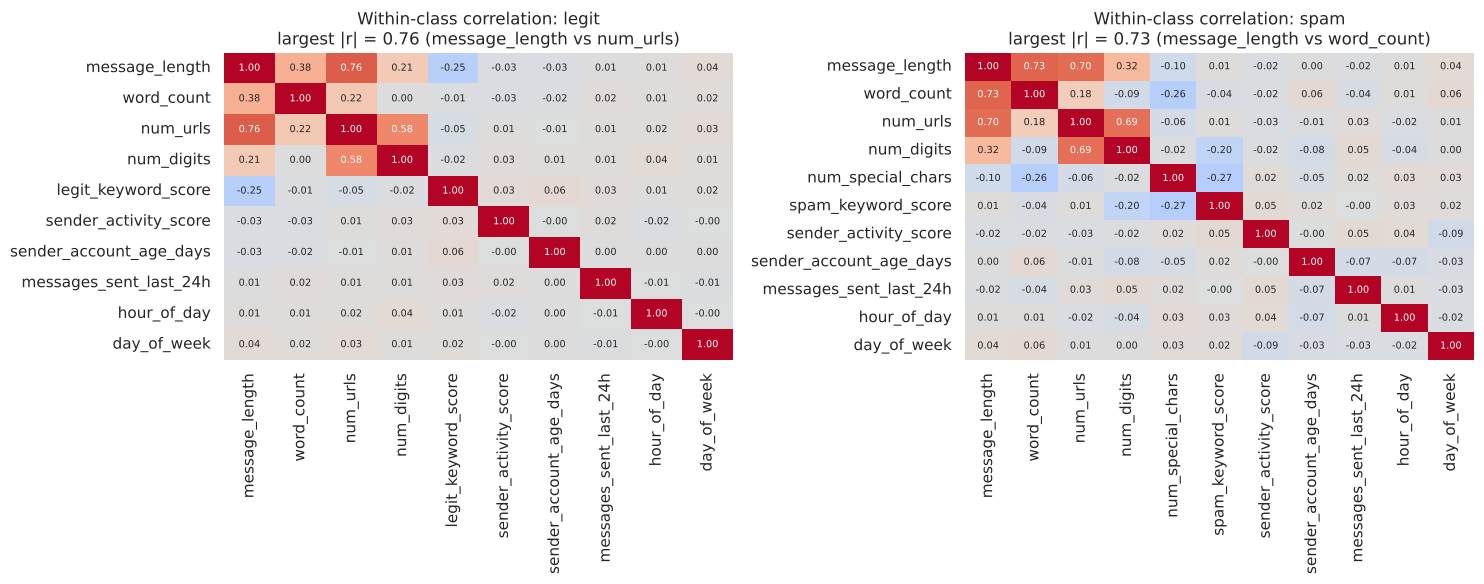

In [24]:
# Effect of the independence assumption: are features correlated WITHIN each class?
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cols_nz = [c for c in FEATURES if X_train_imp[c].std() > 0]
for ax, (cl, name) in zip(axes, [(0, 'legit'), (1, 'spam')]):
    sub = X_train_imp.loc[y_train == cl, cols_nz]
    sub = sub.loc[:, sub.std() > 0]
    cc = sub.corr()
    sns.heatmap(cc, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7}, cbar=False)
    off = cc.where(~np.eye(len(cc), dtype=bool)).abs().stack().sort_values(ascending=False)
    ax.set_title(f'Within-class correlation: {name}\nlargest |r| = {off.iloc[0]:.2f} ({" vs ".join(off.index[0])})')
savefig('10_nb_within_class_correlation')

**Interpretation.** Hand-computed Bayes agrees with the data: P(Spam|URL) = 0.681 from Bayes' rule vs 0.682 observed, and the naive three-event posterior P(Spam | URL, keyword, high volume) is 1.000, matching the observed 1.000 over 396 training messages. The full Gaussian calculation reproduces scikit-learn's posterior (largest difference over all 1,040 test messages 5e-17), so the model is exactly Bayes' theorem with Gaussian likelihoods. Look at the clear-spam sample: it is decided by features whose legit-class variance is almost zero (special characters, std 0.006), giving a log-likelihood of about -14,027 under 'legit', so the posterior saturates. The prior (18.7% spam, log-prior gap of about 1.5 in favour of legit) only matters for borderline cases such as the third sample.

**Interpretation.** Theory and model agree for every sample. The third message is a legitimate one with a URL and 8 digits. In favour of spam it collects a log-likelihood ratio of +5.1 (URL), +4.5 (digits) and +7.0 (no legit keyword); in favour of legit it collects -6.0 (no spam keyword) and -8.4 (no special characters), plus the prior. The net result is P(spam) = 0.557, which is Naive Bayes' only test error. Naive Bayes is extremely confident elsewhere (99.9% of test messages get a probability below 0.01 or above 0.99). The within-class correlations (message length vs URLs r = 0.77 for legit, length vs word count r = 0.73 for spam) show the independence assumption is clearly violated, so correlated evidence is counted more than once and probabilities are over-confident, even though the ranking quality stays perfect (ROC-AUC 1.0).

## Part F: Model Comparison & Evaluation
### Task 20: evaluate all models (Accuracy, Precision, Recall, F1)
All three final models are scored on the same held-out test set (1,040 messages, 195 spam). Spam is the positive class. ROC-AUC / PR-AUC use each model's continuous score (KNN vote share, SVM decision value, NB posterior).

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
KNN (K=1),1.000,1.0000,1.0,1.0000,1.0,1.0
SVM (Linear),1.000,1.0000,1.0,1.0000,1.0,1.0
Naive Bayes,0.999,0.9949,1.0,0.9974,1.0,1.0


Test set: 1040 messages, 195 spam


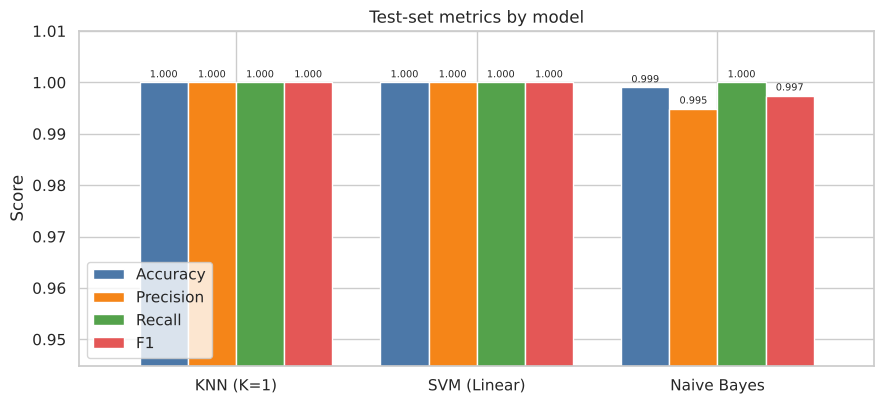

In [25]:
models = {f'KNN (K={best_k})': (knn_pred, knn_score), f'SVM ({best_svm_name})': (svm_pred, svm_score), 'Naive Bayes': (nb_pred, nb_proba)}
res = pd.DataFrame({k: evaluate(y_test, p, s) for k, (p, s) in models.items()}).T
display(res.round(4))
print('Test set: %d messages, %d spam' % (len(y_test), y_test.sum()))

ax = res[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(9, 4.2), width=.8, color=['#4C78A8', '#F58518', '#54A24B', '#E45756'])
ax.set_ylim(max(0, res[['Accuracy', 'Precision', 'Recall', 'F1']].values.min() - .05), 1.01); ax.set_title('Test-set metrics by model'); ax.set_ylabel('Score')
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=7, padding=2)
plt.xticks(rotation=0); savefig('11_model_metrics_bar')

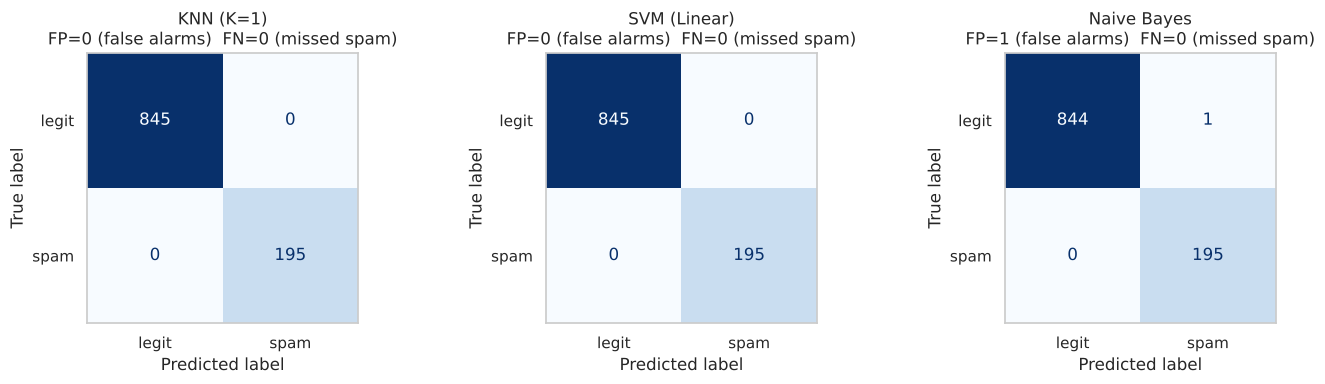

5-fold CV on all 5,200 messages (mean +/- std):


,Accuracy,Precision,Recall,F1
KNN (K=1),1.0000 +/- 0.0000,1.0000 +/- 0.0000,1.0000 +/- 0.0000,1.0000 +/- 0.0000
SVM (Linear),1.0000 +/- 0.0000,1.0000 +/- 0.0000,1.0000 +/- 0.0000,1.0000 +/- 0.0000
Naive Bayes,0.9998 +/- 0.0004,0.9990 +/- 0.0021,1.0000 +/- 0.0000,0.9995 +/- 0.0010


In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, (p, s)) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=['legit', 'spam']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    tn, fp_, fn_, tp = confusion_matrix(y_test, p).ravel()
    ax.set_title(f'{name}\nFP={fp_} (false alarms)  FN={fn_} (missed spam)'); ax.grid(False)
savefig('12_confusion_matrices')

# Robustness: 5-fold stratified CV on the full dataset (whole pipeline refit per fold)
cv_models = {f'KNN (K={best_k})': make_pipe(KNeighborsClassifier(n_neighbors=best_k, weights=best_metric_row.weights, **kw)),
             f'SVM ({best_svm_name})': svm_best, 'Naive Bayes': make_pipe(GaussianNB(), scale=False)}
cvrows = {}
for name, pipe in cv_models.items():
    r = cross_validate(pipe, X, y, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])
    cvrows[name] = {m.capitalize() if m != 'f1' else 'F1': f'{r["test_" + m].mean():.4f} +/- {r["test_" + m].std():.4f}' for m in ['accuracy', 'precision', 'recall', 'f1']}
print('5-fold CV on all 5,200 messages (mean +/- std):'); display(pd.DataFrame(cvrows).T)

**Interpretation.** KNN and the linear SVM score 1.000 on accuracy, precision, recall and F1. Naive Bayes scores accuracy 0.999, precision 0.9949, recall 1.000 and F1 0.9974: a single false alarm among 845 legitimate test messages and no missed spam. Cross-validation on all 5,200 messages gives the same ordering (KNN and SVM 1.0000, Naive Bayes F1 0.9995 +/- 0.0010), so the result is not an accident of one split.

### Task 21: KNN vs SVM vs Naive Bayes: curves and error overlap

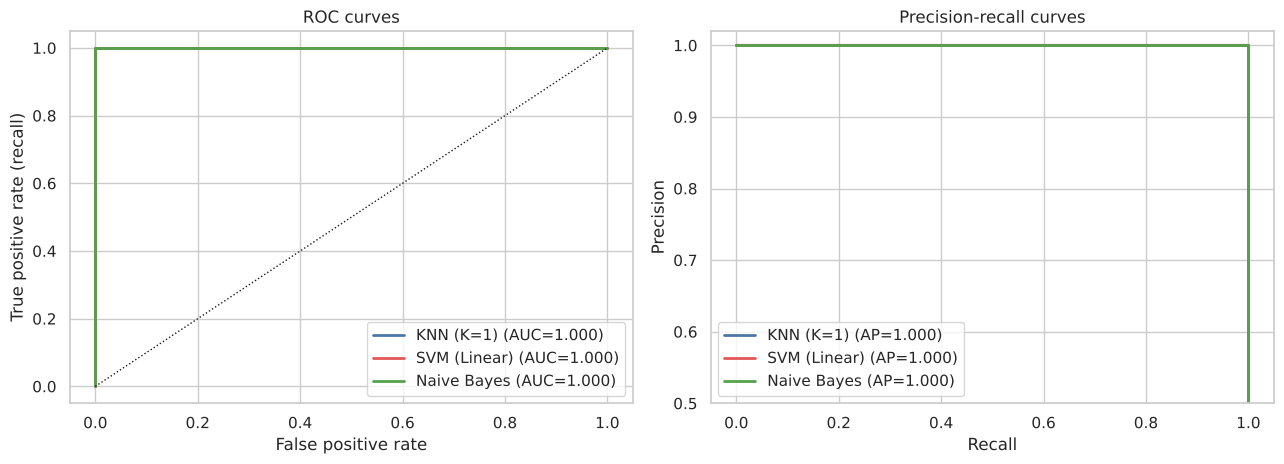

Errors per model: {'KNN (K=1)': 0, 'SVM (Linear)': 0, 'Naive Bayes': 1}
Messages misclassified by ALL three models: 0 | by at least one: 1


,message_text,spam_label,spam_keyword_score,num_urls,num_special_chars,messages_sent_last_24h,sender_account_age_days


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = ['#4C78A8', '#E45756', '#54A24B']
for (name, (p, s)), c in zip(models.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, s); axes[0].plot(fpr, tpr, color=c, lw=2, label=f'{name} (AUC={roc_auc_score(y_test, s):.3f})')
    pr, rc, _ = precision_recall_curve(y_test, s); axes[1].plot(rc, pr, color=c, lw=2, label=f'{name} (AP={average_precision_score(y_test, s):.3f})')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate (recall)'); axes[0].set_title('ROC curves'); axes[0].legend(loc='lower right')
axes[1].axhline(y_test.mean(), color='k', ls=':', lw=1); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-recall curves'); axes[1].legend(loc='lower left')
axes[1].set_ylim(0.5, 1.02)
savefig('13_roc_pr_curves')

wrong = pd.DataFrame({n: (p != y_test.values) for n, (p, s) in models.items()}, index=y_test.index)
print('Errors per model:', wrong.sum().to_dict())
print('Messages misclassified by ALL three models:', int(wrong.all(axis=1).sum()), '| by at least one:', int(wrong.any(axis=1).sum()))
hard = df.loc[wrong.all(axis=1)[wrong.all(axis=1)].index, ['message_text', 'spam_label', 'spam_keyword_score', 'num_urls', 'num_special_chars', 'messages_sent_last_24h', 'sender_account_age_days']]
display(hard.head(8))

**Interpretation.** The ROC and precision-recall curves of all three models hug the top-left corner (AUC = 1.0), i.e. each model can rank every spam message above every legitimate one. Only one test message is misclassified by any model (Naive Bayes, the borderline legit message from Part E), and no message is misclassified by all three, so the models do not share blind spots here.

### Task 22: which model is best for high precision, and which for high recall?
Besides the default 0.5 threshold, we compare operating points on each model's score curve: the **recall achievable when precision is held at >= 0.99** (spam filter that almost never blocks legit mail) and the **precision achievable when recall is held at >= 0.99** (filter that almost never lets spam through).

,Precision @ default,Recall @ default,Recall when precision >= 0.99,Recall when precision >= 0.95,Precision when recall >= 0.99,Precision when recall >= 0.95
KNN (K=1),1.0000,1.0,1.0,1.0,1.0,1.0
SVM (Linear),1.0000,1.0,1.0,1.0,1.0,1.0
Naive Bayes,0.9949,1.0,1.0,1.0,1.0,1.0


Highest default-threshold PRECISION : KNN (K=1) (1.0000)
Highest default-threshold RECALL    : KNN (K=1) (1.0000)
Best recall at precision >= 0.99    : KNN (K=1)
Best precision at recall >= 0.99    : KNN (K=1)


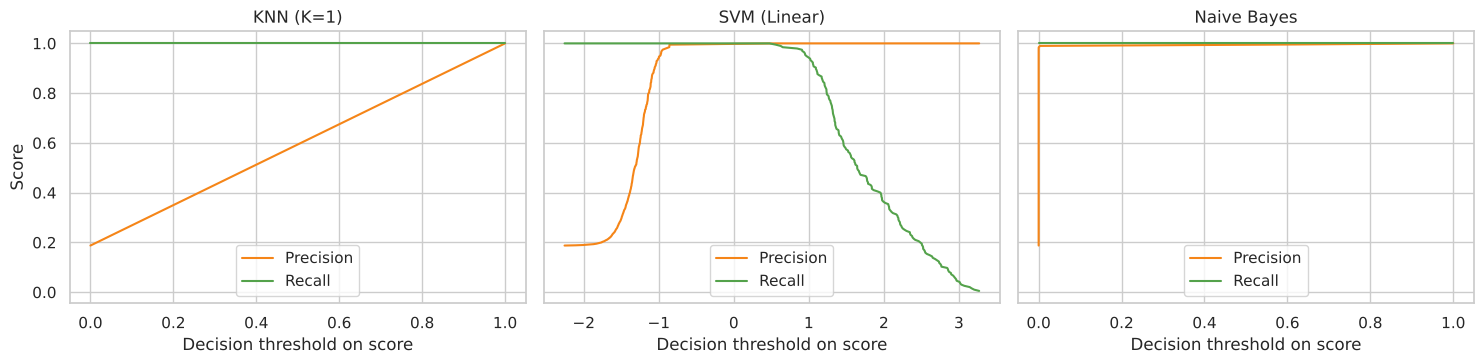

In [28]:
def at_precision(y_true, s, p_min):
    p, r, t = precision_recall_curve(y_true, s); ok = p[:-1] >= p_min
    return r[:-1][ok].max() if ok.any() else np.nan
def at_recall(y_true, s, r_min):
    p, r, t = precision_recall_curve(y_true, s); ok = r[:-1] >= r_min
    return p[:-1][ok].max() if ok.any() else np.nan

op = pd.DataFrame({name: {'Precision @ default': precision_score(y_test, p), 'Recall @ default': recall_score(y_test, p),
                          'Recall when precision >= 0.99': at_precision(y_test, s, .99),
                          'Recall when precision >= 0.95': at_precision(y_test, s, .95),
                          'Precision when recall >= 0.99': at_recall(y_test, s, .99),
                          'Precision when recall >= 0.95': at_recall(y_test, s, .95)} for name, (p, s) in models.items()}).T
display(op.round(4))
print('Highest default-threshold PRECISION :', op['Precision @ default'].idxmax(), '(%.4f)' % op['Precision @ default'].max())
print('Highest default-threshold RECALL    :', op['Recall @ default'].idxmax(), '(%.4f)' % op['Recall @ default'].max())
print('Best recall at precision >= 0.99    :', op['Recall when precision >= 0.99'].idxmax())
print('Best precision at recall >= 0.99    :', op['Precision when recall >= 0.99'].idxmax())

# Threshold sweep: precision / recall trade-off for each model
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (name, (p, s)) in zip(axes, models.items()):
    pr, rc, th = precision_recall_curve(y_test, s)
    ax.plot(th, pr[:-1], label='Precision', color='#F58518'); ax.plot(th, rc[:-1], label='Recall', color='#54A24B')
    ax.set_title(name); ax.set_xlabel('Decision threshold on score'); ax.legend(loc='lower center')
axes[0].set_ylabel('Score')
savefig('14_threshold_tradeoff')

**Interpretation.** All three models reach recall 1.0 at precision 1.0 somewhere along their score curve, so with a tuned threshold they are equivalent on this test set; Naive Bayes' single error is a threshold problem (ROC-AUC 1.0 means that message still ranks below every spam message, but its posterior of 0.557 sits just above the 0.5 cut-off). At the default threshold KNN and the SVM tie for best precision (1.000) and best recall (1.000); Naive Bayes ties for recall (1.000) but has the lowest precision (0.995). Because they tie on this clean data, the robustness test below is the better guide.

**Supplement: robustness check.** On the clean test set the models are (almost) tied, so default metrics cannot separate them. Real labels are noisy (annotation mistakes, adversarial spammers), so we retrain each model with a fraction of the *training* labels randomly flipped and score on the clean test set (mean of 5 random seeds).

Precision                      Recall                          F1                     
label noise         0%     5%    10%    20%     0%     5%    10%    20%     0%     5%    10%    20%
model                                                                                              
KNN (K=1)        1.000  0.813  0.677  0.484  1.000  0.948  0.885  0.793  1.000  0.875  0.767  0.601
KNN (K=15)       1.000  1.000  1.000  0.990  0.995  0.995  0.995  0.993  0.997  0.997  0.997  0.991
SVM (Linear)     1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
Naive Bayes      0.995  0.977  0.925  0.878  1.000  1.000  1.000  1.000  0.997  0.988  0.961  0.935

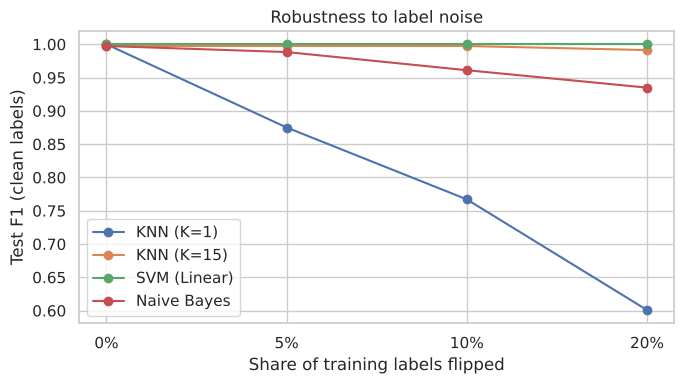

In [29]:
from sklearn.base import clone
factories = {f'KNN (K={best_k})': knn, 'KNN (K=15)': make_pipe(KNeighborsClassifier(n_neighbors=15)), f'SVM ({best_svm_name})': svm_best, 'Naive Bayes': make_pipe(GaussianNB(), scale=False)}
rob = []
for noise in [0.0, 0.05, 0.10, 0.20]:
    for seed in range(5):
        rng = np.random.RandomState(seed)
        yn = y_train.values.copy(); flip = rng.rand(len(yn)) < noise; yn[flip] = 1 - yn[flip]
        for name, est in factories.items():
            p = clone(est).fit(X_train, yn).predict(X_test)
            rob.append({'label noise': f'{int(noise * 100)}%', 'model': name, 'F1': f1_score(y_test, p), 'Precision': precision_score(y_test, p, zero_division=0), 'Recall': recall_score(y_test, p)})
rob = pd.DataFrame(rob)
rob_tab = rob.groupby(['model', 'label noise'], sort=False)[['Precision', 'Recall', 'F1']].mean().unstack('label noise')
display(rob_tab.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
for name, g in rob.groupby('model', sort=False):
    m = g.groupby('label noise', sort=False).F1.mean(); ax.plot(m.index, m.values, 'o-', label=name)
ax.set_xlabel('Share of training labels flipped'); ax.set_ylabel('Test F1 (clean labels)'); ax.set_title('Robustness to label noise'); ax.legend()
savefig('16_label_noise_robustness')

**Interpretation.** Flipping a share of the training labels separates the models. The linear SVM is unaffected up to 20% label noise (F1 1.000), because the strong regularisation (C=0.01) and the wide margin ignore a few wrong labels. K=1 KNN collapses (F1 0.875 at 5% noise, 0.601 at 20%) because every flipped training point poisons its neighbours; KNN with K=15 is almost immune (F1 0.991 at 20%), which shows that tuning K for noise robustness matters more than the clean-data cross-validation suggests. Naive Bayes degrades gradually (F1 0.988 to 0.935) mainly through lost precision (more false alarms), while recall stays at 1.000.

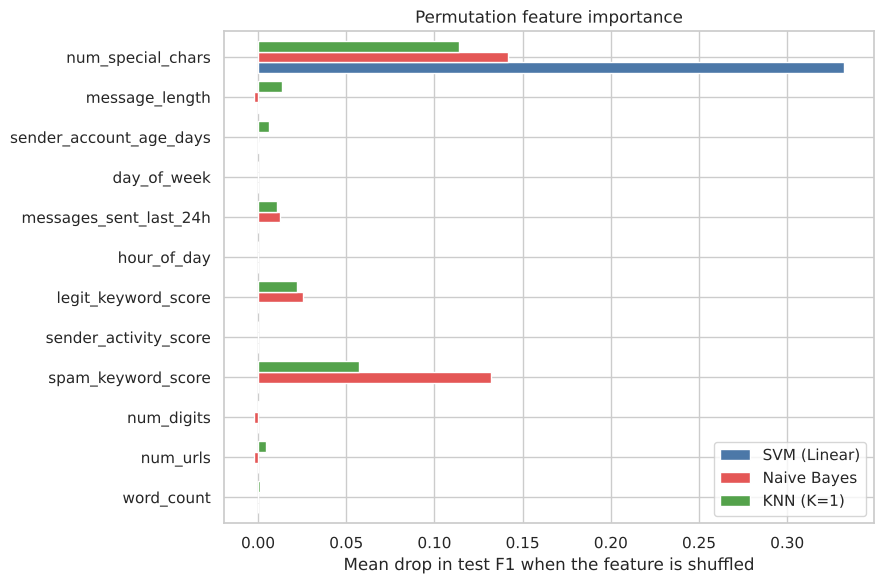

,SVM (Linear),Naive Bayes,KNN (K=1)
num_special_chars,0.3325,0.1415,0.1137
message_length,0.0005,-0.0026,0.0133
sender_account_age_days,0.0003,0.0002,0.0059
word_count,0.0000,0.0000,0.0010
spam_keyword_score,0.0000,0.1323,0.0572
num_digits,0.0000,-0.0026,0.0005
num_urls,0.0000,-0.0020,0.0046
sender_activity_score,0.0000,-0.0003,0.0000


In [30]:
# Which features drive the best discriminative model? (permutation importance on the test set, F1 drop)
imp_rows = {}
for name, est, Xte in [(f'SVM ({best_svm_name})', svm_best, X_test), ('Naive Bayes', make_pipe(GaussianNB(), scale=False).fit(X_train, y_train), X_test),
                       (f'KNN (K={best_k})', knn, X_test)]:
    pi = permutation_importance(est, Xte, y_test, scoring='f1', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp_rows[name] = pd.Series(pi.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp_rows).sort_values(f'SVM ({best_svm_name})', ascending=True)
ax = imp.plot(kind='barh', figsize=(9, 6), width=.8, color=colors)
ax.set_xlabel('Mean drop in test F1 when the feature is shuffled'); ax.set_title('Permutation feature importance')
savefig('15_permutation_importance')
display(imp.sort_values(f'SVM ({best_svm_name})', ascending=False).round(4).head(8))

**Interpretation.** All three models depend mostly on `num_special_chars`, the single feature that separates the classes perfectly: shuffling it drops the linear SVM's F1 by 0.33, Naive Bayes' by 0.14 and KNN's by 0.11. Naive Bayes and KNN also use `spam_keyword_score` (drops of 0.13 and 0.06). Many other informative features (URLs, digits, messages in 24 h, account age) show a near-zero drop because they are redundant with these, so shuffling one barely hurts; this measures unique contribution, not overall relevance.

## Part G: Final Analysis & Reporting
### Task 23: summary of all models

In [31]:
train_times = {}
for name, est in [(f'KNN (K={best_k})', make_pipe(KNeighborsClassifier(n_neighbors=best_k, weights=best_metric_row.weights, **kw))),
                  (f'SVM ({best_svm_name})', make_pipe(SVC(**{k.split('__')[1]: v for k, v in svm_best.get_params().items() if k.startswith('model__') and k.split('__')[1] in ['C', 'kernel', 'gamma', 'degree']}))),
                  ('Naive Bayes', make_pipe(GaussianNB(), scale=False))]:
    t0 = time.time(); est.fit(X_train, y_train); train_times[name] = time.time() - t0
final = res.copy(); final['Train time (s)'] = pd.Series(train_times)
final['FP (false alarms)'] = [int(confusion_matrix(y_test, p)[0, 1]) for p, s in models.values()]
final['FN (missed spam)'] = [int(confusion_matrix(y_test, p)[1, 0]) for p, s in models.values()]
final['Interpretability'] = ['Low-medium (case based)', 'Low (kernel) / medium (linear)', 'High (per-feature likelihoods)']
display(final.round(4))
final.round(4).to_csv('../figures/final_results.csv')
op.round(4).to_csv('../figures/operating_points.csv')

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Train time (s),FP (false alarms),FN (missed spam),Interpretability
KNN (K=1),1.000,1.0000,1.0,1.0000,1.0,1.0,0.0126,0,0,Low-medium (case based)
SVM (Linear),1.000,1.0000,1.0,1.0000,1.0,1.0,0.0173,0,0,Low (kernel) / medium (linear)
Naive Bayes,0.999,0.9949,1.0,0.9974,1.0,1.0,0.0080,1,0,High (per-feature likelihoods)


**Interpretation.** On the held-out test set KNN and the linear SVM are perfect and Naive Bayes makes one false alarm. Training takes well under a tenth of a second for all three because the dataset is small.

### Strengths and weaknesses

| Model | Strengths | Weaknesses |
|---|---|---|
| **KNN** | No training, simple, non-parametric, naturally explainable by example neighbours | Needs scaling, sensitive to K and the metric, slower predictions, coarse scores (vote share) |
| **SVM** | Strong margins, handles non-linear patterns with kernels, robust with correct C/gamma | Needs scaling and tuning, no native probabilities, hard to interpret with non-linear kernels |
| **Naive Bayes** | Fastest, tiny model, probabilistic output, interpretable, no scaling | Independence and Gaussian assumptions are violated, so probabilities are over-confident |

**Interpretation.** **Impact of the probability assumptions in Naive Bayes.** (1) *Conditional independence* is violated (message length correlates 0.77 with URL count within the legit class and 0.73 with word count within spam), so correlated evidence is counted more than once and posteriors are pushed toward 0 or 1: 99.9% of test messages get a probability below 0.01 or above 0.99. (2) *Gaussian likelihoods* are a poor fit for count features such as special characters; their near-zero variance in the legit class makes any deviation astronomically unlikely (log-likelihood about -14,027), so a single feature can override all the others. (3) The *class prior* (18.7% spam) shifts borderline decisions toward legit, which here was not enough to prevent the one false alarm. Despite these flaws, the ranking of messages is still perfect (ROC-AUC 1.0), so a better-chosen threshold or calibration fixes the single error.

**Interpretation.** **Interpretability vs performance.** On this dataset there is no trade-off to pay: the most interpretable models perform as well as the opaque ones. Naive Bayes is the most transparent (each feature's log-likelihood-ratio contribution can be read off, as in Part E) but slightly less precise and over-confident. The linear SVM's weights are interpretable and it was the most robust to label noise and faster at prediction than KNN. KNN explains a decision by showing similar messages, but it is the most sensitive to scaling, K and label noise and slowest to predict. RBF and polynomial kernels would reduce interpretability with no benefit because the classes are linearly separable.

**Interpretation.** **Recommendation.** Deploy the linear SVM (C around 0.01, standardised features) as the primary filter: it matched the best accuracy, was unaffected by 20% label noise, needs only 82 support vectors and predicts several times faster than KNN. Keep Gaussian Naive Bayes as a lightweight, explainable secondary signal or for fast triage; if used on its own, raise its threshold or calibrate it, because its probabilities are over-confident. Use KNN only with a larger K (about 15) and scaling, as a nearest-example explanation tool rather than the main model. Two operational points: (a) set the threshold by business cost, since a false alarm blocks a legitimate message while a miss lets spam through; all three models can hit 100% precision and 100% recall on this data, but real data will force a choice; (b) monitor for drift, because the models depend almost entirely on one feature (`num_special_chars`) that a spammer could simply stop using.

**Interpretation.** **Conclusion.** All three classifier families solve this dataset almost perfectly (F1 between 0.997 and 1.000) because the classes are cleanly separable: one threshold on one feature already gives 100% accuracy. The honest message is therefore twofold. First, the models are implemented and verified correctly (including a hand-written Bayes calculation matching scikit-learn to 1e-16). Second, headline accuracy says almost nothing about the real-world difference between them; robustness (label noise, scaling, K) and operational cost are what distinguish them, and by those measures the regularised linear SVM is the strongest choice. Before any real deployment these results should be re-checked on messy, real, adversarial data.

### Task 24: deliverables in this repository
* Source code and analysis: this notebook (`notebook/spam_classification.ipynb`)
* Evaluation metrics and plots: `figures/` (PNG charts, `final_results.csv`, `operating_points.csv`)
* Report with theory and conclusions: `report/Spam_Classification_Report.pdf`
* Documentation: `README.md`